In [52]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import brier_score_loss
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import (precision_recall_curve, PrecisionRecallDisplay)
from sklearn.calibration import calibration_curve, CalibrationDisplay

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold


In [2]:
X_train = pd.read_csv("C:/Users/slmkc/Downloads/PhaseI/Churn_model/data/processed/X_train.csv")

Y_train = pd.read_csv("C:/Users/slmkc/Downloads/PhaseI/Churn_model/data/processed/Y_train.csv")["Churn"]

In [3]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
lr_plain = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000))

In [4]:
#assumption case study:
value_saved = 800 #if churner is retained
cost_contact = 100 #cost of holding churner
success_rate = 0.25 #share of contacted churner who stay

oof_prob = cross_val_predict(lr_plain, X_train, Y_train, cv = cv, method = "predict_proba")[:,1]

Y_arr = Y_train.values


In [5]:
rows = []

for t in np.arange(0.05, 0.96, 0.05):
    flagged = oof_prob >= t
    flagged_int = flagged.astype(int)
    n_flagged = flagged.sum()
    n_hit = (flagged & (Y_arr == 1)).sum()
    profit = n_hit * success_rate * value_saved - n_flagged * cost_contact

    rows.append({
        "threshold": round(t,2),
        "flagged_pct": round(flagged.mean() * 100, 1),
        "precision": round(precision_score(Y_arr, flagged_int, zero_division = 0), 3),
        "recall": round(recall_score(Y_arr, flagged_int), 3),
        "profit_per_customer": round(profit / len(Y_arr), 1),
    })
    

In [6]:
threshold_table = pd.DataFrame(rows)
print(threshold_table.to_string(index = False))

best_row = threshold_table.loc[threshold_table["profit_per_customer"].idxmax()]

chosen_t = best_row["threshold"]

everyone = (Y_arr.sum() * success_rate * value_saved - len(Y_arr) * cost_contact) / len(Y_arr)


 threshold  flagged_pct  precision  recall  profit_per_customer
      0.05         72.6      0.356   0.974                -20.9
      0.10         62.1      0.403   0.942                -12.1
      0.15         55.4      0.436   0.911                 -7.1
      0.20         47.7      0.478   0.859                 -2.1
      0.25         42.6      0.508   0.815                  0.7
      0.30         37.6      0.539   0.765                  3.0
      0.35         32.9      0.574   0.712                  4.9
      0.40         29.1      0.597   0.656                  5.7
      0.45         24.9      0.627   0.589                  6.3
      0.50         21.3      0.663   0.532                  7.0
      0.55         17.9      0.692   0.467                  6.9
      0.60         14.6      0.716   0.394                  6.3
      0.65         11.1      0.731   0.307                  5.1
      0.70          7.8      0.780   0.229                  4.4
      0.75          4.5      0.815   0.1

In [7]:
print("Best threshold", chosen_t, " | profit per customer", best_row["profit_per_customer"])

print("Customer everyone: profit per customer =", round(everyone, 1), "| contact nobody = 0")

Best threshold 0.5  | profit per customer 7.0
Customer everyone: profit per customer = -46.9 | contact nobody = 0


In [8]:
for sr in [0.15, 0.25, 0.40]:
    best_profit, best_t = -999999, None

    for t in np.arange(0.05, 0.96, 0.05):
        flagged = oof_prob >= t

        n_hit = (flagged & (Y_arr == 1)).sum()

        profit = (n_hit * sr * value_saved - flagged.sum() * cost_contact) / len(Y_arr)

        if profit > best_profit:
            best_profit, best_t = profit, round(t, 2)

    print("Success rate", sr, "| best threshold:", best_t, "| profit per customer:", round(best_profit, 1), "| break even probability:", round(cost_contact / (sr * value_saved), 2))

Success rate 0.15 | best threshold: 0.8 | profit per customer: 0.2 | break even probability: 0.83
Success rate 0.25 | best threshold: 0.5 | profit per customer: 7.0 | break even probability: 0.5
Success rate 0.4 | best threshold: 0.35 | profit per customer: 27.6 | break even probability: 0.31


In [9]:
X_test = pd.read_csv("C:/Users/slmkc/Downloads/PhaseI/Churn_model/data/processed/X_test.csv")

Y_test = pd.read_csv("C:/Users/slmkc/Downloads/PhaseI/Churn_model/data/processed/Y_test.csv")["Churn"]

In [10]:
Y_test_arr = Y_test.values

n = len(Y_test_arr)

print(X_test.shape, Y_test.shape)

(1409, 27) (1409,)


In [11]:
final_models = {
    "Logistic Regression (primary)": make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000)),

    "Tuned Gradient Boosting (Challenge)": HistGradientBoostingClassifier(
        max_iter = 200, learning_rate = 0.05, max_depth = 2, max_leaf_nodes = 31, min_samples_leaf = 20, l2_regularization = 5, random_state = 42),
}



In [12]:
test_probs = {}

for name, model in final_models.items():
    model.fit(X_train, Y_train)
    test_probs[name] = model.predict_proba(X_test)[:,1]
    

In [15]:
#Bootstrap:

rng = np.random.default_rng(42)

boot_idx = []

for i in range(1000):
    boot_idx.append(rng.integers(0, n, n))

boot_auc = {}
for name, p in test_probs.items():
    aucs = []
    for idx in boot_idx:
        aucs.append(roc_auc_score(Y_test_arr[idx], p[idx]))
    boot_auc[name]= np.array(aucs)
    low, high = np.percentile(aucs, [2.5, 97.5])
    print(name)
    print("ROC-AUC", round(roc_auc_score(Y_test_arr, p), 4), "| 95% range", round(low, 4), "to", round(high, 4))
    print("PR-AUC", round(average_precision_score(Y_test_arr, p), 4), "| random guessing give", round(Y_test_arr.mean(), 3))
    print("Brier", round(brier_score_loss(Y_test_arr, p), 4))

names = list(test_probs.keys())

diff = boot_auc[names[1]]-boot_auc[names[0]]
low, high = np.percentile(diff, [2.5,97.5])

print("Challenger - primary (ROC-AUC): 95% range", round(low, 4), "to", round(high, 4))



Logistic Regression (primary)
ROC-AUC 0.8413 | 95% range 0.8196 to 0.8621
PR-AUC 0.6286 | random guessing give 0.265
Brier 0.1384
Tuned Gradient Boosting (Challenge)
ROC-AUC 0.844 | 95% range 0.8222 to 0.8648
PR-AUC 0.656 | random guessing give 0.265
Brier 0.1363
Challenger - primary (ROC-AUC): 95% range -0.0036 to 0.0092


In [16]:
primary = test_probs["Logistic Regression (primary)"]

flagged = primary >= chosen_t

tn, fp, fn, tp = confusion_matrix(Y_test_arr, flagged.astype(int)).ravel()


In [17]:
print("Threshold used", chosen_t)

print("Left alone and stayed (TN)", tn)

print("Contacted but have stayed (FP, wasted offer)", fp)

print("Missed churners (FN, lost customers)", fn)

print("Churner we contacted (TP)", tp)

print("Precision", round(tp / (tp+fp), 3), "| Recall", round(tp/(tp+fn), 3))

print("Share of customers contacted", round(flagged.mean() * 100, 1), "%")


Threshold used 0.5
Left alone and stayed (TN) 931
Contacted but have stayed (FP, wasted offer) 104
Missed churners (FN, lost customers) 174
Churner we contacted (TP) 200
Precision 0.658 | Recall 0.535
Share of customers contacted 21.6 %


In [18]:
profit_model = (tp * success_rate * value_saved - (tp + fp) * cost_contact) /n

profit_everyone = (Y_test_arr.sum() * success_rate * value_saved -n * cost_contact) / n



In [19]:
print("Profit per customer, model-based", round(profit_model, 1), "| Contact everyone", round(profit_everyone, 1), "| Contact nobody : 0")

Profit per customer, model-based 6.8 | Contact everyone -46.9 | Contact nobody : 0


In [23]:
order = np.argsort(-primary)

sorted_y = Y_test_arr[order]

rows = []

for pct in [10, 20, 30, 40, 50]:
    k = int(n*pct / 100)
    caught = sorted_y[:k].sum()
    rows.append({"Contact_top_pct": pct,
                 "Customers":k,
                 "Churners_caught": caught,
                 "hit_rate_pct": round(caught / k*100, 1),
                 "share_of_all_churners_pct": round(caught / Y_test_arr.sum() * 100, 1),
                 "lift": round((caught / k )/ Y_test_arr.mean(), 2)})


In [24]:
print(pd.DataFrame(rows).to_string(index = False))

 Contact_top_pct  Customers  Churners_caught  hit_rate_pct  share_of_all_churners_pct  lift
              10        140              103          73.6                       27.5  2.77
              20        281              182          64.8                       48.7  2.44
              30        422              246          58.3                       65.8  2.20
              40        563              287          51.0                       76.7  1.92
              50        704              328          46.6                       87.7  1.76


In [26]:
os.makedirs("C:/Users/slmkc/Downloads/PhaseI/Churn_model/reports", exist_ok = True)


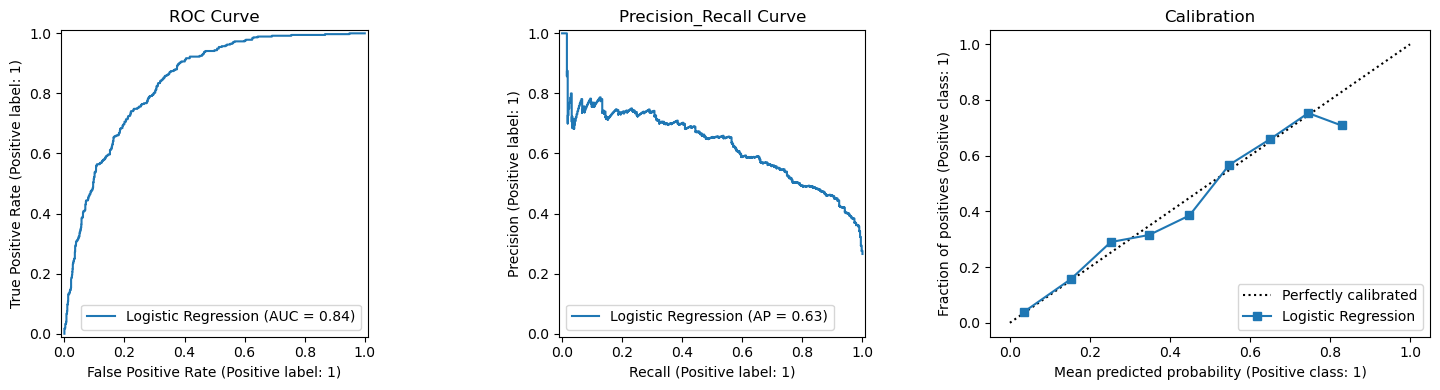

In [33]:
fig, axes = plt.subplots(1, 3, figsize = (15,4))

RocCurveDisplay.from_predictions(Y_test_arr, primary, ax = axes[0], name = "Logistic Regression")

PrecisionRecallDisplay.from_predictions(Y_test_arr, primary, ax = axes[1], name = "Logistic Regression")

CalibrationDisplay.from_predictions(Y_test_arr, primary, n_bins = 10, ax = axes[2], name = "Logistic Regression")

axes[0].set_title("ROC Curve")
axes[1].set_title("Precision_Recall Curve")
axes[2].set_title("Calibration")

plt.tight_layout()

plt.savefig("C:/Users/slmkc/Downloads/PhaseI/Churn_model/reports/figures/step7_test_curves.png", dpi = 150)

plt.show()

In [34]:
print(list(X_test.columns))

['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'num_addons', 'is_first_year', 'monthly_echeck', 'lives_alone', 'gender_Male', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [36]:
lr_final = final_models["Logistic Regression (primary)"]

coefs = lr_final.named_steps["logisticregression"].coef_[0]

In [37]:
coef_table = pd.DataFrame({"feature": X_train.columns, "weight": coefs})
coef_table["effect_on_odds"] = np.exp(coef_table["weight"])
coef_table = coef_table.sort_values("weight", ascending = False)

In [38]:
print("Raise churn risk the most")
print(coef_table.head(8).round(3).to_string(index = False))


Raise churn risk the most
                       feature  weight  effect_on_odds
   InternetService_Fiber optic   0.749           2.115
                  TotalCharges   0.264           1.303
                 is_first_year   0.252           1.287
               StreamingMovies   0.235           1.265
                   StreamingTV   0.233           1.262
                 MultipleLines   0.225           1.252
PaymentMethod_Electronic check   0.215           1.240
              PaperlessBilling   0.184           1.202


In [39]:
print("Lower churn risk the most")
print(coef_table.tail(8).round(3).to_string(index = False))

Lower churn risk the most
           feature  weight  effect_on_odds
        Dependents  -0.102           0.903
       TechSupport  -0.113           0.893
    OnlineSecurity  -0.139           0.870
 Contract_One year  -0.306           0.737
InternetService_No  -0.600           0.549
 Contract_Two year  -0.649           0.523
    MonthlyCharges  -0.775           0.461
            tenure  -0.782           0.458


In [42]:
segments = {
    "Month-to-month contract": (X_test["Contract_One year"] == 0) & (X_test["Contract_Two year"] == 0),
    "One or two-year contract": (X_test["Contract_One year"] == 1) | (X_test["Contract_Two year"] == 1),
    "First year (tenure <= 12)": X_test["is_first_year"] ==1,
    "After first year": X_test["is_first_year"]==0,
    "Senior Citizen": X_test["SeniorCitizen"] == 1,
    "Fiber Optic": X_test["InternetService_Fiber optic"] == 1,
    "Live alone": X_test["lives_alone"] == 1,
}


In [47]:
pred = flagged.astype(int)

rows = []

for name, mask in segments.items():
    m = mask.values
    churners = Y_test_arr[m].sum()
    caught = ((pred == 1) & (Y_test_arr == 1) & m).sum()
    rows.append({
        "segment": name,
        "customers": m.sum(),
        "churn_rate_pct": round(churners / m.sum() * 100, 1),
        "churners_missed": churners - caught,
        "recall_pct": round(caught / churners * 100, 1)})

In [48]:
print(pd.DataFrame(rows).to_string(index = False))

                  segment  customers  churn_rate_pct  churners_missed  recall_pct
  Month-to-month contract        773            42.6              130        60.5
 One or two-year contract        636             7.1               44         2.2
First year (tenure <= 12)        449            47.9               66        69.3
         After first year        960            16.6              108        32.1
           Senior Citizen        222            44.1               37        62.2
              Fiber Optic        613            41.1               80        68.3
               Live alone        666            34.8               87        62.5


In [50]:
boot_pr = {}

for name, p in test_probs.items():
    vals = []
    for idx in boot_idx:
        vals.append(average_precision_score(Y_test_arr[idx], p[idx]))
    boot_pr[name] = np.array(vals)

In [51]:
diff_pr = boot_pr[names[1]] - boot_pr[names[0]]

low, high = np.percentile(diff_pr, [2.5, 97.5])

print("Challenger - Primary (PR-AUC): 95% range", round(low, 4), "to", round(high, 4))

Challenger - Primary (PR-AUC): 95% range 0.0079 to 0.0483


In [57]:
fresh_cv = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 2, random_state = 7)

X_no_gender = X_train.drop(columns = ["gender_Male"])

with_g = cross_val_score(lr_plain, X_train, Y_train, cv =  fresh_cv, scoring = "roc_auc")

without_g = cross_val_score(lr_plain, X_no_gender, Y_train, cv = fresh_cv, scoring = "roc_auc")


In [58]:
print("With gender", round(with_g.mean(), 4))

print("without gender", round(without_g.mean(), 4))

print("Difference", round((without_g - with_g).mean(), 4))

With gender 0.8466
without gender 0.8467
Difference 0.0001
